# 01 · Limpieza y filtrado del dataset (@AppleSupport) con Apache Spark

**Objetivo:** partir del CSV completo de *Customer Support on Twitter* (~3 millones de tweets de muchas marcas) y producir un conjunto de datos que contenga **solo** la conversación de @AppleSupport: lo que los clientes le escriben y lo que Apple responde.

**Por qué Spark y Parquet:** Spark procesa el CSV en paralelo. El resultado filtrado se convierte a pandas y se guarda como un archivo Parquet con PyArrow.

**Qué produce:** `data/processed/apple_support_filtrado.parquet` y una tabla de conteos paso a paso (van en la sección de *Resultados* de la tesis).

**Requisitos (Windows + Anaconda):**
- `pip install pyspark pandas pyarrow matplotlib`
- Tener Java 8, 11 o 17 instalado (`java -version` en la terminal).
- La conversión final de Spark a pandas carga el resultado filtrado en memoria. Si el conjunto no cabe en la memoria disponible, puede ser necesario guardar desde Spark usando `winutils.exe` en Windows.

## 1. Sesión de Spark y rutas
`SparkSession` es el punto de entrada de Spark. Se configura en modo local usando todos los núcleos (`local[*]`), 4 GB de memoria y pocas particiones de *shuffle* (suficiente para una sola computadora). La opción `legacy.timeParserPolicy` permite interpretar fechas en varios formatos más adelante.

Las rutas se convierten a URI (`file:///...`) porque Spark en Windows lo prefiere así.

In [1]:
from pathlib import Path
import pandas as pd
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder.master("local[*]").appName("tesis_limpieza")
         .config("spark.driver.memory", "1g")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.legacy.timeParserPolicy", "LEGACY")
         .getOrCreate())

RAW = Path("../data/raw/twcs.csv").resolve().as_uri()
OUT = Path("../data/processed/apple_support_filtrado.parquet").resolve()
BRAND = "AppleSupport"
conteo = {}   # aquí se registra cuántos tweets quedan en cada paso

## 2. Carga del CSV
Los tweets contienen saltos de línea y comillas dentro del texto, por eso se activan `multiLine` y `escape`. Todas las columnas se leen como **texto**: así los identificadores de 18-19 dígitos no pierden precisión.

In [2]:
df = (spark.read.option("header", True)
                .option("multiLine", True)
                .option("escape", '"')
                .csv(RAW))
conteo["total_original"] = df.count()
df.printSchema()
df.limit(5).toPandas()

root
 |-- tweet_id: string (nullable = true)
 |-- author_id: string (nullable = true)
 |-- inbound: string (nullable = true)
 |-- created_at: string (nullable = true)
 |-- text: string (nullable = true)
 |-- response_tweet_id: string (nullable = true)
 |-- in_response_to_tweet_id: string (nullable = true)



,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id
0,1,sprintcare,False,Tue Oct 31 22:10:47 +0000 2017,@115712 I understand. I would like to assist y...,2,3
1,2,115712,True,Tue Oct 31 22:11:45 +0000 2017,@sprintcare and how do you propose we do that,NaN,1
2,3,115712,True,Tue Oct 31 22:08:27 +0000 2017,@sprintcare I have sent several private messag...,1,4
3,4,sprintcare,False,Tue Oct 31 21:54:49 +0000 2017,@115712 Please send us a Private Message so th...,3,5
4,5,115712,True,Tue Oct 31 21:49:35 +0000 2017,@sprintcare I did.,4,6


## 3. Filtro de @AppleSupport
Se construyen dos grupos y se unen:

1. **Respuestas de Apple:** `author_id == "AppleSupport"`.
2. **Tweets de clientes dirigidos a Apple:** los que *mencionan* `@AppleSupport` **o** a los que Apple respondió (aunque el cliente no haya puesto la mención, por ejemplo, dentro de un hilo).

Para saber a qué tweets respondió Apple se toma la columna "responde a" de sus respuestas y se hace un `left_semi` join (conserva los tweets de clientes cuyo id aparece ahí, sin duplicar filas).

In [3]:
apple = df.filter(F.col("author_id") == BRAND).withColumn("rol", F.lit("apple"))

respondidos = (apple.select(F.col("in_response_to_tweet_id").alias("tweet_id"))
                    .where(F.col("tweet_id").isNotNull()).distinct())

clientes = df.filter(F.lower(F.col("inbound")) == "true")
menciona = clientes.filter(F.col("text").rlike("(?i)@applesupport"))
contestados = clientes.join(respondidos, on="tweet_id", how="left_semi")

filtrado = (apple.unionByName(menciona.unionByName(contestados)
                                       .withColumn("rol", F.lit("cliente"))))
conteo["tras_filtro_apple"] = filtrado.count()

## 4. Depuración
- Se eliminan **duplicados** por `tweet_id` (un tweet podía entrar por mención *y* por haber sido respondido).
- Se eliminan textos **vacíos**.
- Se interpreta la **fecha**. Se intentan dos formatos: el original de Kaggle (`Tue Oct 31 22:10:47 +0000 2017`) y `dd/MM/yyyy HH:mm:ss`. Si ninguno funciona la fecha queda nula y el tweet se descarta (se cuenta cuántos fueron).

In [4]:
d = filtrado.dropDuplicates(["tweet_id"])
conteo["tras_quitar_duplicados"] = d.count()

d = d.filter(F.col("text").isNotNull() & (F.trim(F.col("text")) != ""))
conteo["tras_quitar_vacios"] = d.count()

f = F.col("created_at")
d = d.withColumn("fecha", F.coalesce(
        F.to_timestamp(f, "EEE MMM dd HH:mm:ss Z yyyy"),
        F.to_timestamp(f, "dd/MM/yyyy HH:mm:ss"),
        F.to_timestamp(f)))
conteo["fechas_invalidas"] = d.filter(F.col("fecha").isNull()).count()
d = d.filter(F.col("fecha").isNotNull())

## 5. Normalización del texto
Se crea `texto_limpio` y se conserva el original en `text`:
- apóstrofes tipográficos (’ ‘ `) → ' (si no, "isn’t" no coincidiría con las reglas);
- enlaces → `<URL>`;
- menciones a otros usuarios → `@USER` (privacidad y menos ruido), salvo `@AppleSupport`;
- espacios repetidos → uno solo.

No se pasa a minúsculas ni se quitan emojis: los modelos como BERTweet los aprovechan, y las reglas del notebook 02 ya ignoran mayúsculas.

In [5]:
t = F.regexp_replace("text", "[’‘`]", "'")
t = F.regexp_replace(t, r"https?://\S+", "<URL>")
t = F.regexp_replace(t, r"@(?!(?i:applesupport)\b)\w+", "@USER")
t = F.trim(F.regexp_replace(t, r"\s+", " "))

d = (d.withColumn("texto_limpio", t)
      .withColumn("n_palabras", F.size(F.split("texto_limpio", " ")))
      .select("tweet_id", "rol", "author_id", "fecha", "text", "texto_limpio",
              "n_palabras", "in_response_to_tweet_id")
      .cache())
d.limit(5).toPandas()

,tweet_id,rol,author_id,fecha,text,texto_limpio,n_palabras,in_response_to_tweet_id
0,1000003,cliente,497667,2017-11-05 05:33:26,@AppleSupport https://t.co/OnHabGwPo7,@AppleSupport <URL>,2,999856
1,1000023,apple,AppleSupport,2017-11-03 16:45:53,@356755 We'd be happy to look this over with y...,@USER We'd be happy to look this over with you...,24,1000024
2,1000077,apple,AppleSupport,2017-11-03 16:57:27,@356765 We're here to help. What happens when ...,@USER We're here to help. What happens when yo...,28,1000078
3,1000092,cliente,356770,2017-11-03 12:52:55,"@AppleSupport your c/s sucks, I was just disco...","@AppleSupport your c/s sucks, I was just disco...",15,NaN
4,1000186,cliente,356792,2017-11-03 12:43:38,@115858 @AppleSupport y’all need to fix this ...,@USER @AppleSupport y'all need to fix this fr ...,16,NaN


## 6. Resumen para la sección de Resultados
Documenta cuántos tweets había al inicio, cuántos quedaron tras cada paso y la composición final.

In [6]:
por_rol = {r["rol"]: r["count"] for r in d.groupBy("rol").count().collect()}
conteo["tweets_clientes"] = por_rol.get("cliente", 0)
conteo["respuestas_apple"] = por_rol.get("apple", 0)
rango = d.agg(F.min("fecha").alias("a"), F.max("fecha").alias("b")).first()
conteo["fecha_inicio"], conteo["fecha_fin"] = str(rango["a"]), str(rango["b"])
pd.Series(conteo, name="valor").to_frame()

,valor
total_original,2811774
tras_filtro_apple,311379
tras_quitar_duplicados,232973
tras_quitar_vacios,232973
fechas_invalidas,0
tweets_clientes,126113
respuestas_apple,106860
fecha_inicio,2016-03-03 07:00:08
fecha_fin,2017-12-03 17:12:28


## 7. Exploración rápida
Longitud de los tweets (en palabras) y volumen diario. Los picos de volumen pueden corresponder a incidentes reales y sirven para describir el conjunto de datos.

+-------+-----------------+
|summary|       n_palabras|
+-------+-----------------+
|  count|           232973|
|   mean|20.37012014267748|
| stddev|9.259212279520792|
|    min|                1|
|    max|               94|
+-------+-----------------+



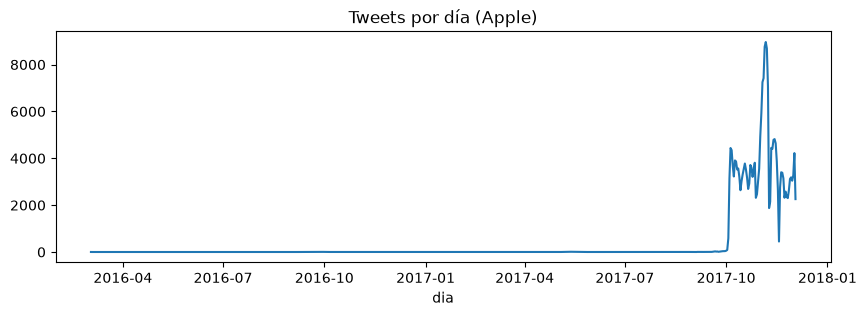

In [7]:
d.select("n_palabras").describe().show()
por_dia = (d.groupBy(F.to_date("fecha").alias("dia")).count().orderBy("dia").toPandas())
por_dia.set_index("dia")["count"].plot(figsize=(10, 3), title="Tweets por día (Apple)");

## 8. Guardado en Parquet
El DataFrame filtrado se convierte a pandas y se guarda como un único archivo Parquet con PyArrow. El notebook 02 lee este archivo directamente.

In [8]:
pdf = d.toPandas()
pdf.to_parquet(OUT, index=False, engine="pyarrow", compression="snappy")
print("Guardado:", OUT, "|", len(pdf), "filas")

Guardado: C:\Users\julia\OneDrive\Escritorio\MCD\Tesis\proyecto_investigacion\data\processed\apple_support_filtrado.parquet | 232973 filas
